In [38]:
import mne
from mne_bids import BIDSPath, read_raw_bids, mark_channels
import numpy as np

# Raw Data Inspection

In [ ]:
#NOTE: change the subject for your analysis
# subjects = ["001"] and ["002"] used the sentence experiemnt, subcjets = ["009"] used the word experiment
subjects = ["002"]

In [ ]:
bids_root = "../2026N400_demo"    #NOTE: change this to the root of the dataset
deriv_root = bids_root + "/derivatives" 
sessions = ["001"]
task = "n400"
runs = ["1"]
ch_types = ["eeg"]
data_type = "eeg"

bids_path = BIDSPath(
    subject=subjects[0],
    session=sessions[0],
    task=task,
    run=runs[0],
    datatype=data_type,
    root=bids_root,
    extension="set"
)

raw = read_raw_bids(bids_path=bids_path, verbose=False)

/var/folders/t4/tpd64s9d2xb_cdt_fwtwlr480000gn/T/ipykernel_50312/1188318105.py:19: RuntimeWarning: Data will be preloaded. preload=False or a string preload is not supported when the data is stored in the .set file
  raw = read_raw_bids(bids_path=bids_path, verbose=False)


In [ ]:
# use this to plot the interactive raw waveforms
raw.plot()

# ERP plotting

- these are for the plotting of the ERP (Event-relaed Reponse). 

- 0s is the onset of the critical word (in sentence experiment) or the second word (in the word experiment)

- N400 component usually shows up at around 0.4s, and theoretically the incongruent condition should have a lower N400 than the congruent condition (but unfortunately we could hardly see the effect here)

- signals from `["L8", "Z8", "R8","L7","R7"]` electrodes (correspond to the central parietal area of the brain cortex) are averaged as from literature N400 tends to be stronger here. You can also change the channels to see how the positions we look at change the results


Reading /Users/qianyueli/2026N400_demo/derivatives/sub-002/ses-001/eeg/sub-002_ses-001_task-n400_ave.fif ...
    Read a total of 1 projection items:
        Average EEG reference (1 x 67) active
    Found the data of interest:
        t =    -200.00 ...     800.00 ms (kongruent)
        0 CTF compensation matrices available
        nave = 43 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Applying baseline correction (mode: mean)
    Read a total of 1 projection items:
        Average EEG reference (1 x 67) active
    Found the data of interest:
        t =    -200.00 ...     800.00 ms (inkongruent)
        0 CTF compensation matrices available
        nave = 43 - aspect type = 100
Projections have already been applied. Setting proj attribute to True.
Applying baseline correction (mode: mean)
    Read a total of 1 projection items:
        Average EEG reference (1 x 67) active
    Found the data of interest:
        t =    -200.00 ...     800.

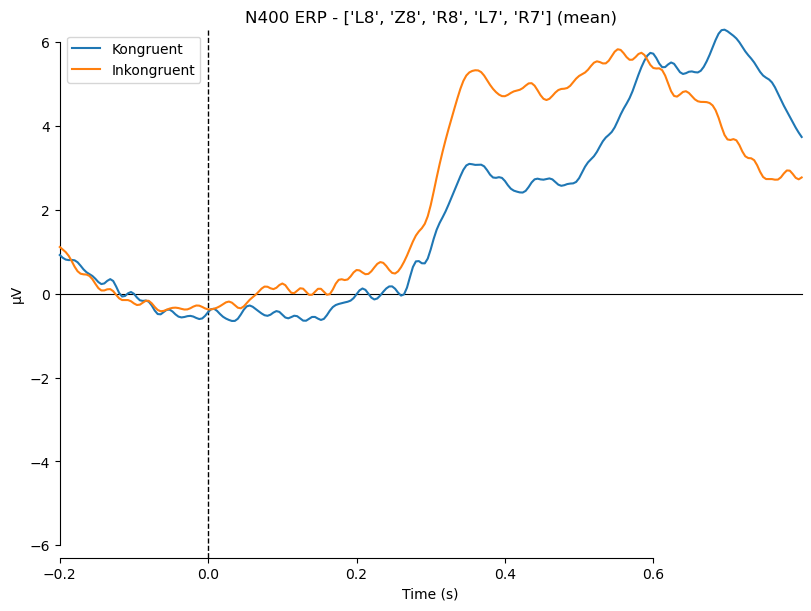

[<Figure size 800x600 with 1 Axes>]

In [48]:
ave_path = deriv_root + f"/sub-{subjects[0]}/ses-001/eeg/sub-{subjects[0]}_ses-001_task-n400_ave.fif"

evokeds = mne.read_evokeds(ave_path, baseline=(None, 0))

evoked_dict = {ev.comment: ev for ev in evokeds}

evoked_k = evoked_dict["kongruent"]
evoked_i = evoked_dict["inkongruent"]

evoked_k.interpolate_bads(reset_bads=True)
evoked_i.interpolate_bads(reset_bads=True)

# central parietal electrodes for N400 analysis
n400_roi = ["L8", "Z8", "R8", "L7", "R7"]
#n400_roi = ["Z8"]

valid_roi = [
    ch for ch in n400_roi
    if ch in evoked_k.ch_names
    and ch in evoked_i.ch_names
    and ch not in evoked_k.info["bads"]
    and ch not in evoked_i.info["bads"]
]

mne.viz.plot_compare_evokeds(
    {
        "Kongruent": evoked_dict["kongruent"],
        "Inkongruent": evoked_dict["inkongruent"],
    },
    picks=valid_roi,
    combine="mean",
    invert_y=False,
    title=f"N400 ERP - {valid_roi}",
)